# Dataset B — RealMLP final 15-feature report

## tl;dr

RealMLP final run `realmlp_final_15f_20261004_01` is a frozen 15-raw / 19-semantic-feature benchmark. Five-fold Train-only mean ROC-AUC is **0.8639** (SD **0.0021**). Validation selected threshold **0.726** with balanced accuracy **0.7866**. On Test, ROC-AUC is **0.8632** and balanced accuracy is **0.7828**; all 1,000 locked bootstrap replicates are valid.

## Context & Methods

This is a read-only reporting notebook for the final RealMLP run. It validates and displays persisted common-schema reporting files only. It does not train, refit, transform holdout data, select a threshold, run inference, or regenerate bootstrap indices.

### Key Assumptions

- `split_v1` membership and ordering are authoritative.
- Approved is the positive class for ROC-AUC and probability calibration.
- Denied-oriented precision, recall, F1, and average precision use the complementary class consistently.
- Confidence intervals are percentile intervals from the existing 1,000 locked Test bootstrap replicates.

In [1]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import SVG, display

start = Path.cwd().resolve()
PROJECT_ROOT = next(
    candidate for candidate in (start, *start.parents)
    if (candidate / 'src').is_dir() and (candidate / 'config' / 'dataset_b').is_dir()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.dataset_b.reporting.model_reporting import validate_reporting_directory

RUN_ID = 'realmlp_final_15f_20261004_01'
RUN_ROOT = PROJECT_ROOT / 'artifacts' / 'dataset_b' / 'realmlp' / 'final' / RUN_ID
REPORTING_DIR = RUN_ROOT / 'reporting'
summary = validate_reporting_directory(REPORTING_DIR)
assert (RUN_ROOT / 'FROZEN').is_file()
{'status': summary['reporting_status'], 'run_id': summary['run_id'], 'frozen': True}


W1004 19:14:20.463000 21884 .venv-realmlp-gpu\Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels
D:\Proj\DAP\DAP391m_GR12\.venv-realmlp-gpu\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


{'status': 'COMPLETE',
 'run_id': 'realmlp_final_15f_20261004_01',
 'frozen': True}

## Data

The source is the frozen run-scoped reporting package under `artifacts/dataset_b/realmlp/final/<run_id>/reporting`. The package links the final full-Train model, ordered Test predictions, and locked-index bootstrap results.

In [2]:
cv = pd.read_csv(REPORTING_DIR / 'cv_fold_metrics.csv')
metrics = pd.read_csv(REPORTING_DIR / 'rq1_metrics_long.csv')
confusion = pd.read_csv(REPORTING_DIR / 'confusion_matrix.csv')
calibration = pd.read_csv(REPORTING_DIR / 'calibration_curve.csv')

{
    'raw_features': 15,
    'semantic_features': 19,
    'train_rows': summary['data_boundaries']['train_rows'],
    'validation_rows': summary['data_boundaries']['validation_rows'],
    'test_rows': summary['data_boundaries']['test_rows'],
    'threshold': summary['validation']['threshold'],
}


{'raw_features': 15,
 'semantic_features': 19,
 'train_rows': 205310,
 'validation_rows': 43995,
 'test_rows': 43996,
 'threshold': 0.726}

## Results

Exact persisted values remain in the reporting CSV/JSON files. Tables below use four decimal places for presentation only.

### Train-only cross-validation

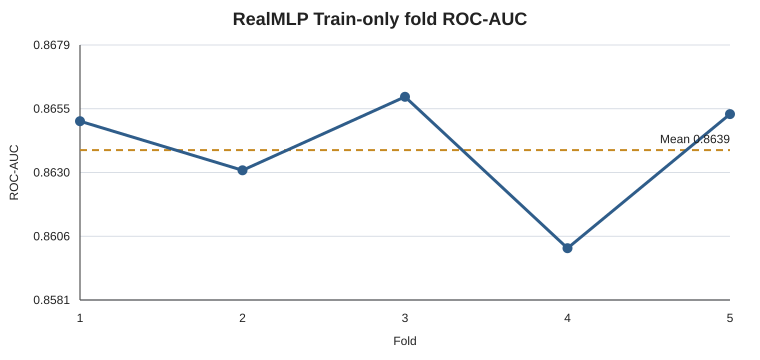

,fold,roc_auc,fit_seconds
0,1,0.8650,376.7
1,2,0.8631,515.7
2,3,0.8659,548.3
3,4,0.8601,582.6
4,5,0.8653,504.5


In [3]:
width, height = 760, 360
left, right, top, bottom = 80, 30, 45, 60
plot_width, plot_height = width - left - right, height - top - bottom
y_min = float(cv['roc_auc'].min()) - 0.002
y_max = float(cv['roc_auc'].max()) + 0.002
x_pos = lambda fold: left + (float(fold) - 1) / 4 * plot_width
y_pos = lambda value: top + (y_max - float(value)) / (y_max - y_min) * plot_height
parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">', '<style>text{font-family:Arial,sans-serif;fill:#222}.label{font-size:12px}.title{font-size:18px;font-weight:600}.grid{stroke:#D9DEE5;stroke-width:1}.axis{stroke:#555;stroke-width:1.2}</style>', '<rect width="100%" height="100%" fill="white"/>', '<text class="title" x="380" y="25" text-anchor="middle">RealMLP Train-only fold ROC-AUC</text>']
for tick in range(5):
    value = y_min + tick * (y_max - y_min) / 4
    y_tick = y_pos(value)
    parts += [f'<line class="grid" x1="{left}" y1="{y_tick:.1f}" x2="{width-right}" y2="{y_tick:.1f}"/>', f'<text class="label" x="{left-10}" y="{y_tick+4:.1f}" text-anchor="end">{value:.4f}</text>']
points = ' '.join(f'{x_pos(row.fold):.1f},{y_pos(row.roc_auc):.1f}' for row in cv.itertuples())
mean_roc_auc = float(cv['roc_auc'].mean())
mean_y = y_pos(mean_roc_auc)
parts += [f'<line class="axis" x1="{left}" y1="{top}" x2="{left}" y2="{height-bottom}"/>', f'<line class="axis" x1="{left}" y1="{height-bottom}" x2="{width-right}" y2="{height-bottom}"/>', f'<line x1="{left}" y1="{mean_y:.1f}" x2="{width-right}" y2="{mean_y:.1f}" stroke="#C68A22" stroke-width="2" stroke-dasharray="7 5"/>', f'<polyline points="{points}" fill="none" stroke="#2F5D8A" stroke-width="3"/>']
for row in cv.itertuples():
    x, y = x_pos(row.fold), y_pos(row.roc_auc)
    parts += [f'<circle cx="{x:.1f}" cy="{y:.1f}" r="5" fill="#2F5D8A"/>', f'<text class="label" x="{x:.1f}" y="{height-bottom+22}" text-anchor="middle">{int(row.fold)}</text>']
parts += [f'<text class="label" x="{width-right}" y="{mean_y-7:.1f}" text-anchor="end" fill="#8A5C00">Mean {mean_roc_auc:.4f}</text>', f'<text class="label" x="{left+plot_width/2:.1f}" y="{height-15}" text-anchor="middle">Fold</text>', f'<text class="label" x="18" y="{top+plot_height/2:.1f}" text-anchor="middle" transform="rotate(-90 18 {top+plot_height/2:.1f})">ROC-AUC</text>', '</svg>']
display(SVG(''.join(parts)))

cv_display = cv[['fold', 'roc_auc', 'fit_seconds']].copy()
cv_display['roc_auc'] = cv_display['roc_auc'].round(4)
cv_display['fit_seconds'] = cv_display['fit_seconds'].round(1)
cv_display


### Test metrics and 95% bootstrap intervals

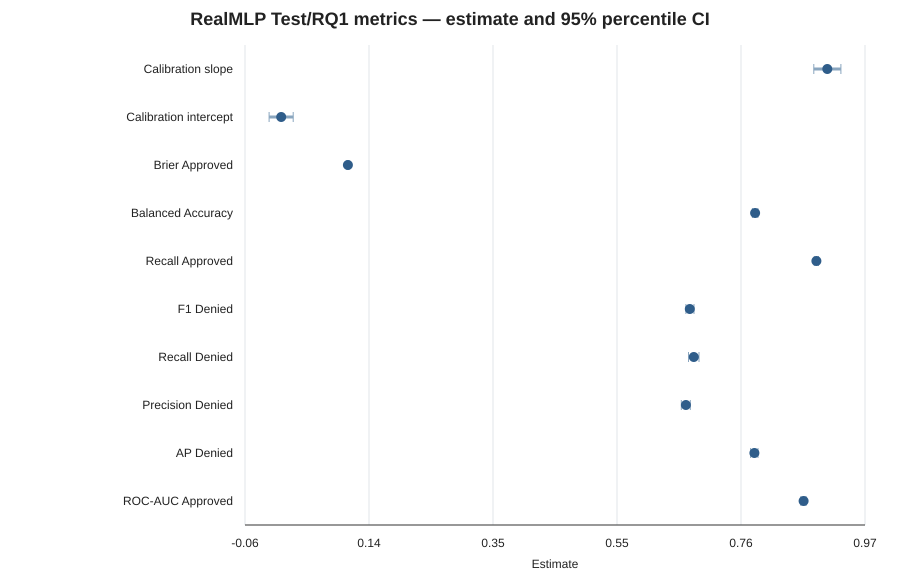

,metric,estimate,ci_low,ci_high,valid_replicates
0,roc_auc_approved,0.8632,0.8587,0.8673,1000
1,average_precision_denied,0.7816,0.7753,0.7875,1000
2,precision_denied,0.6678,0.6601,0.6751,1000
3,recall_denied,0.6810,0.6722,0.6897,1000
4,f1_denied,0.6743,0.6678,0.6812,1000
5,recall_approved,0.8846,0.8811,0.8880,1000
6,balanced_accuracy,0.7828,0.7782,0.7874,1000
7,brier_score_approved,0.1065,0.1048,0.1084,1000
8,calibration_intercept,-0.0043,-0.0243,0.0158,1000
9,calibration_slope,0.9027,0.8802,0.9252,1000


In [4]:
metric_order = [
    'roc_auc_approved', 'average_precision_denied', 'precision_denied',
    'recall_denied', 'f1_denied', 'recall_approved', 'balanced_accuracy',
    'brier_score_approved', 'calibration_intercept', 'calibration_slope',
]
metric_labels = {
    'roc_auc_approved': 'ROC-AUC Approved',
    'average_precision_denied': 'AP Denied',
    'precision_denied': 'Precision Denied',
    'recall_denied': 'Recall Denied',
    'f1_denied': 'F1 Denied',
    'recall_approved': 'Recall Approved',
    'balanced_accuracy': 'Balanced Accuracy',
    'brier_score_approved': 'Brier Approved',
    'calibration_intercept': 'Calibration intercept',
    'calibration_slope': 'Calibration slope',
}
plot_data = metrics.set_index('metric').loc[metric_order].reset_index().iloc[::-1].reset_index(drop=True)
width, height = 900, 580
left, right, top, bottom = 245, 35, 45, 55
plot_width, plot_height = width-left-right, height-top-bottom
x_min = float(plot_data['ci_low'].min()) - 0.04
x_max = float(plot_data['ci_high'].max()) + 0.04
x_pos = lambda value: left + (float(value)-x_min)/(x_max-x_min)*plot_width
y_pos = lambda row: top + (row + 0.5) / len(plot_data) * plot_height
parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">', '<style>text{font-family:Arial,sans-serif;fill:#222}.label{font-size:12px}.title{font-size:18px;font-weight:600}.grid{stroke:#E1E5EA;stroke-width:1}.axis{stroke:#555;stroke-width:1.2}</style>', '<rect width="100%" height="100%" fill="white"/>', '<text class="title" x="450" y="25" text-anchor="middle">RealMLP Test/RQ1 metrics — estimate and 95% percentile CI</text>']
for tick in range(6):
    value = x_min + tick*(x_max-x_min)/5
    x = x_pos(value)
    parts += [f'<line class="grid" x1="{x:.1f}" y1="{top}" x2="{x:.1f}" y2="{height-bottom}"/>', f'<text class="label" x="{x:.1f}" y="{height-bottom+22}" text-anchor="middle">{value:.2f}</text>']
for row_index, row in plot_data.iterrows():
    y = y_pos(row_index)
    low, estimate, high = x_pos(row.ci_low), x_pos(row.estimate), x_pos(row.ci_high)
    parts += [f'<text class="label" x="{left-12}" y="{y+4:.1f}" text-anchor="end">{metric_labels[row.metric]}</text>', f'<line x1="{low:.1f}" y1="{y:.1f}" x2="{high:.1f}" y2="{y:.1f}" stroke="#8AA6BF" stroke-width="3"/>', f'<line x1="{low:.1f}" y1="{y-5:.1f}" x2="{low:.1f}" y2="{y+5:.1f}" stroke="#8AA6BF"/>', f'<line x1="{high:.1f}" y1="{y-5:.1f}" x2="{high:.1f}" y2="{y+5:.1f}" stroke="#8AA6BF"/>', f'<circle cx="{estimate:.1f}" cy="{y:.1f}" r="5" fill="#2F5D8A"/>']
parts += [f'<line class="axis" x1="{left}" y1="{height-bottom}" x2="{width-right}" y2="{height-bottom}"/>', f'<text class="label" x="{left+plot_width/2:.1f}" y="{height-12}" text-anchor="middle">Estimate</text>', '</svg>']
display(SVG(''.join(parts)))

metric_display = metrics.set_index('metric').loc[metric_order, ['estimate', 'ci_low', 'ci_high', 'valid_replicates']].reset_index()
metric_display[['estimate', 'ci_low', 'ci_high']] = metric_display[['estimate', 'ci_low', 'ci_high']].round(4)
metric_display


### Test calibration

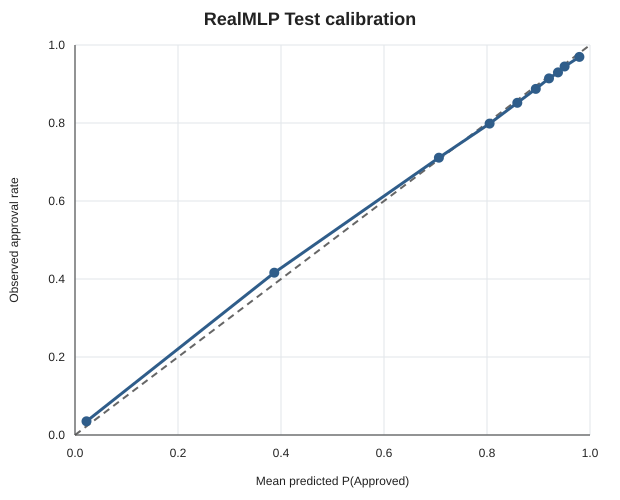

In [5]:
width, height = 620, 500
left, right, top, bottom = 75, 30, 45, 65
plot_width, plot_height = width-left-right, height-top-bottom
x_pos = lambda value: left + float(value)*plot_width
y_pos = lambda value: top + (1-float(value))*plot_height
parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">', '<style>text{font-family:Arial,sans-serif;fill:#222}.label{font-size:12px}.title{font-size:18px;font-weight:600}.grid{stroke:#E1E5EA;stroke-width:1}.axis{stroke:#555;stroke-width:1.2}</style>', '<rect width="100%" height="100%" fill="white"/>', '<text class="title" x="310" y="25" text-anchor="middle">RealMLP Test calibration</text>']
for tick in range(6):
    value=tick/5
    x,y=x_pos(value),y_pos(value)
    parts += [f'<line class="grid" x1="{left}" y1="{y:.1f}" x2="{width-right}" y2="{y:.1f}"/>', f'<line class="grid" x1="{x:.1f}" y1="{top}" x2="{x:.1f}" y2="{height-bottom}"/>', f'<text class="label" x="{left-10}" y="{y+4:.1f}" text-anchor="end">{value:.1f}</text>', f'<text class="label" x="{x:.1f}" y="{height-bottom+22}" text-anchor="middle">{value:.1f}</text>']
points=' '.join(f'{x_pos(row.mean_p_approved):.1f},{y_pos(row.observed_approval_rate):.1f}' for row in calibration.itertuples())
parts += [f'<line x1="{x_pos(0):.1f}" y1="{y_pos(0):.1f}" x2="{x_pos(1):.1f}" y2="{y_pos(1):.1f}" stroke="#666" stroke-width="2" stroke-dasharray="7 5"/>', f'<polyline points="{points}" fill="none" stroke="#2F5D8A" stroke-width="3"/>']
for row in calibration.itertuples():
    parts.append(f'<circle cx="{x_pos(row.mean_p_approved):.1f}" cy="{y_pos(row.observed_approval_rate):.1f}" r="5" fill="#2F5D8A"/>')
parts += [f'<line class="axis" x1="{left}" y1="{top}" x2="{left}" y2="{height-bottom}"/>', f'<line class="axis" x1="{left}" y1="{height-bottom}" x2="{width-right}" y2="{height-bottom}"/>', f'<text class="label" x="{left+plot_width/2:.1f}" y="{height-15}" text-anchor="middle">Mean predicted P(Approved)</text>', f'<text class="label" x="18" y="{top+plot_height/2:.1f}" text-anchor="middle" transform="rotate(-90 18 {top+plot_height/2:.1f})">Observed approval rate</text>', '</svg>']
display(SVG(''.join(parts)))


### Test confusion matrix and closure checks

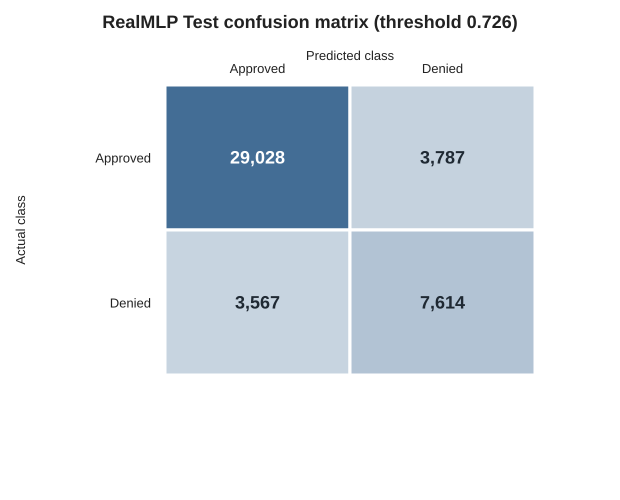

predicted_class,approved,denied
actual_class,,
approved,29028,3787
denied,3567,7614


{'reporting_status': 'COMPLETE',
 'cv_folds': 5,
 'required_metrics': 10,
 'all_bootstrap_replicates_valid': True,
 'calibration_bins': 10,
 'confusion_total': 43996}

In [6]:
confusion_table = confusion.pivot(index='actual_class', columns='predicted_class', values='count').loc[['approved', 'denied'], ['approved', 'denied']]
width, height = 620, 500
left, top, cell_width, cell_height = 165, 85, 185, 145
maximum = int(confusion_table.to_numpy().max())
parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">', '<style>text{font-family:Arial,sans-serif;fill:#222}.label{font-size:13px}.title{font-size:18px;font-weight:600}.value{font-size:18px;font-weight:600}</style>', '<rect width="100%" height="100%" fill="white"/>', f'<text class="title" x="310" y="28" text-anchor="middle">RealMLP Test confusion matrix (threshold {summary["validation"]["threshold"]:.3f})</text>', '<text class="label" x="350" y="60" text-anchor="middle">Predicted class</text>', '<text class="label" x="25" y="230" text-anchor="middle" transform="rotate(-90 25 230)">Actual class</text>']
labels=['Approved','Denied']
for index,label in enumerate(labels):
    parts += [f'<text class="label" x="{left+index*cell_width+cell_width/2}" y="{top-12}" text-anchor="middle">{label}</text>', f'<text class="label" x="{left-14}" y="{top+index*cell_height+cell_height/2+5}" text-anchor="end">{label}</text>']
for row in range(2):
    for column in range(2):
        value=int(confusion_table.iloc[row,column])
        opacity=0.18+0.72*value/maximum
        x,y=left+column*cell_width,top+row*cell_height
        text_color='white' if value/maximum>0.52 else '#1F2933'
        parts += [f'<rect x="{x}" y="{y}" width="{cell_width}" height="{cell_height}" fill="#2F5D8A" fill-opacity="{opacity:.3f}" stroke="white" stroke-width="3"/>', f'<text class="value" x="{x+cell_width/2}" y="{y+cell_height/2+6}" text-anchor="middle" fill="{text_color}" style="fill:{text_color}">{value:,}</text>']
parts.append('</svg>')
display(SVG(''.join(parts)))

closure_checks = {
    'reporting_status': summary['reporting_status'],
    'cv_folds': len(cv),
    'required_metrics': len(metrics),
    'all_bootstrap_replicates_valid': bool(metrics['valid_replicates'].eq(1000).all()),
    'calibration_bins': len(calibration),
    'confusion_total': int(confusion['count'].sum()),
}
display(confusion_table)
closure_checks


## Takeaways

- Fold ROC-AUC is stable: **0.8601–0.8659**, with mean **0.8639** and SD **0.0021**.
- The Validation-selected threshold is **0.726**; Test balanced accuracy is **0.7828**.
- Test ROC-AUC is **0.8632** and denied-class average precision is **0.7816**.
- Calibration slope is **0.9027** and intercept is **−0.0043**.
- All 1,000 locked bootstrap replicates are valid. This notebook makes no cross-model significance, causal, fairness, or legal claim.